# CO₂ bug in the FUT land-only spin-up

**What happened.** The FUT LCC land-only spin-up (`I2100ssp585Clm50BgcCropCplHist_f19_f19-20260924`, script `22b`) ran 100 years with the compset default **CO₂ = 284.32 ppm** (`CLM_CO2_TYPE = constant`). Every coupled FUT run sees **≈1140 ppm**.

**Natural control.** The PD land-only spin-up (`I2000…-20260925`, script `12b`) has the same set-up, but its CO₂ (367 ppm) matches its coupled runs. If the FUT collapse comes from CO₂, PD should show no collapse.

**How to read the figures.**
- x-axis = **land years since the shared starting state**: the coupled spin-up (1–20) is shared by both branches.
  - CTRL branch: nudged run at 21–30.
  - LCC branch: land-only 21–120 → coupled spin-up 121–140 → nudged 141–150.
- **Regions:**
  - *modified cells*: `PCT_NAT_PFT` differs, so LCC ≠ CTRL is expected (the signal).
  - *>45°N unmodified* and *tropics*: identical surfdata, so LCC − CTRL should be ≈ 0 there; any gap is spin-up history.
- Jumps at stage boundaries come from a change of forcing (land-only datm ↔ coupled, free ↔ nudged), not from drift.

Evidence tags: **(a)** verified · **(b)** inference · **(c)** unverified. Run on Betzy in `lcc-env`. The first run reads ~800 history files (~15 min); annual means are cached in `check_CO2_bug_in_land_only_outputs/cache/`.

In [1]:
import os
os.environ.setdefault('HDF5_USE_FILE_LOCKING', 'FALSE')  # before netCDF4/xarray import: HDF5 locking on /cluster/home corrupted cache files
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats, optimize
import netCDF4
import pickle
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

ARCHIVE = Path('/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN_archive')
CASE_ROOT = Path('~/cases/BRL_FRST_XPSN').expanduser()
MASK_FILE = Path('../lcc-modified-cells/modified_cells.nc')
OUT = Path('check_CO2_bug_in_land_only_outputs')
CACHE = OUT / 'cache'  # regenerable annual-mean .nc
CACHE.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False

# Land-state lineage per period, oldest first. handed_on = model years completed when the restart was handed on.
STAGES = pd.DataFrame([
    ('PD',  'PD_spinup',        'shared', 'NF2000norbc_tropstratchem_spinup_f19_f19',                    'coupled',   20),
    ('PD',  'CTRL_PD',          'CTRL',   'NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925',        'nudged',    np.nan),
    ('PD',  'PD_landonly_LCC',  'LCC',    'I2000Clm50BgcCropCplHist_f19_f19-20260925',                   'land-only', 100),
    ('PD',  'PD_spinup_LCC',    'LCC',    'NF2000norbc_tropstratchem_spinup_lcc_f19_f19-20260928',       'coupled',   20),
    ('PD',  'LCC_PD',           'LCC',    'NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261005',         'nudged',    np.nan),
    ('FUT', 'FUT_spinup',       'shared', 'NF2100ssp585norbc_tropstratchem_spinup_f19_f19-3',            'coupled',   20),
    ('FUT', 'CTRL_FUT',         'CTRL',   'NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20260925',  'nudged',    np.nan),
    ('FUT', 'FUT_landonly_LCC', 'LCC',    'I2100ssp585Clm50BgcCropCplHist_f19_f19-20260924',             'land-only', 100),
    ('FUT', 'FUT_spinup_LCC',   'LCC',    'NF2100ssp585norbc_tropstratchem_spinup_lcc_f19_f19-20260928', 'coupled',   20),
    ('FUT', 'LCC_FUT',          'LCC',    'NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261005',   'nudged',    np.nan),
], columns=['period', 'stage', 'branch', 'case', 'kind', 'handed_on']).set_index('stage')

VARS = ['TLAI', 'TSAI', 'HTOP', 'TOTVEGC', 'GPP']  # TSAI/HTOP are missing in some stages (skipped there)
LINEAGE_VARS = ['TLAI', 'TOTVEGC']
NUDGED_YEARS = (2001, 2009)
COLOR = {'shared': '0.35', 'CTRL': '#1f77b4', 'LCC': '#d95f02'}

## 1. CO₂ per stage

`CLM_CO2_TYPE` and `CCSM_CO2_PPMV` are read from each case's `env_run.xml`. With `constant`, CLM uses `CCSM_CO2_PPMV`; with `diagnostic`, it uses the atmosphere's CO₂.
"CO₂ seen" = median of `PCO2 / PBOT` in the last h0 file, where the field exists. It is not in the land-only output or the LCC coupled spin-ups.

In [2]:
def hist_files(case):
    files = sorted((ARCHIVE / case / 'lnd/hist').glob('*.clm2.h0.*.nc'))
    if not files:
        raise FileNotFoundError(f'No clm2.h0 files for {case}')
    return files

def xml_value(case, key):
    for root in (CASE_ROOT, CASE_ROOT / 'BRL_FRST_XPSN_archive'):
        for xml in sorted((root / case).glob('env_*.xml')):
            match = re.search(rf'<entry id="{key}" value="([^"]*)"', xml.read_text())
            if match:
                return match.group(1)
    return 'n/a'

rows = []
for stage, s in STAGES.iterrows():
    with netCDF4.Dataset(hist_files(s.case)[-1]) as d:
        seen = float(np.ma.median(d['PCO2'][:] / d['PBOT'][:]) * 1e6) if {'PCO2', 'PBOT'} <= set(d.variables) else np.nan
    rows.append(dict(stage=stage, period=s.period, branch=s.branch, kind=s.kind,
                     CLM_CO2_TYPE=xml_value(s.case, 'CLM_CO2_TYPE'), CCSM_CO2_PPMV=xml_value(s.case, 'CCSM_CO2_PPMV'),
                     co2_seen_ppm=round(seen, 1)))
co2 = pd.DataFrame(rows).set_index('stage')
co2.to_csv(OUT / 'co2_per_stage.csv')
display(co2)

,period,branch,kind,CLM_CO2_TYPE,CCSM_CO2_PPMV,co2_seen_ppm
stage,,,,,,
PD_spinup,PD,shared,coupled,diagnostic,367.0,370.3
CTRL_PD,PD,CTRL,nudged,diagnostic,367.0,370.3
PD_landonly_LCC,PD,LCC,land-only,constant,367.0,NaN
PD_spinup_LCC,PD,LCC,coupled,diagnostic,367.0,NaN
LCC_PD,PD,LCC,nudged,diagnostic,367.0,370.3
FUT_spinup,FUT,shared,coupled,diagnostic,284.32,1134.0
CTRL_FUT,FUT,CTRL,nudged,diagnostic,284.32,1142.0
FUT_landonly_LCC,FUT,LCC,land-only,constant,284.32,NaN
FUT_spinup_LCC,FUT,LCC,coupled,diagnostic,284.32,NaN


## 2. Annual means

Annual means are weighted by the `time_bounds` length; each interval goes to its midpoint year, and years with less than 365 days are dropped. Spatial weights are `area × landfrac`.

In [3]:
SOIL, SOIL_INDEX = {}, None  # soil fields: see the _six_variables copy

N_WORKERS = 8  # parallel file readers

def read_file(path):
    # Plain netCDF4: ~0.3 s per file on NIRD vs ~5 s with xarray.open_dataset (decoding all 52 variables).
    with netCDF4.Dataset(path) as d:
        t = d['time']
        assert t.calendar == 'noleap' and re.fullmatch(r'days since \d{4}-01-01( 00:00:00)?', t.units), (path, t.units)
        bounds = d['time_bounds'][:].astype(float)
        mid = bounds.mean(1)  # each interval goes to its midpoint year (bounds start 30 min early)
        out = dict(mid=mid, year=int(t.units.split()[2][:4]) + np.floor(mid / 365).astype(int),
                   days=bounds[:, 1] - bounds[:, 0])
        for v in VARS:
            if v in d.variables:
                out[v] = np.ma.filled(d[v][:].astype(float), np.nan)
        for new, old in SOIL.items():
            if old in d.variables:
                assert abs(float(d['levgrnd'][SOIL_INDEX]) - 1.06) < 0.01, f'{path}: soil levels changed'
                assert len(d.dimensions['levsoi']) <= len(d.dimensions['levgrnd'])
                out[new] = np.ma.filled(d[old][:, SOIL_INDEX].astype(float), np.nan)
    return out

def annual_means(case):
    files = hist_files(case)
    try:
        with ProcessPoolExecutor(N_WORKERS, mp_context=mp.get_context('fork')) as pool:
            parts = list(pool.map(read_file, files))
    except pickle.PicklingError:  # cells exec'd outside a kernel (read_file not in __main__): read serially
        parts = [read_file(f) for f in files]
    mid = np.concatenate([p['mid'] for p in parts])
    if len(np.unique(mid)) != len(mid):
        raise ValueError(f'{case}: duplicated time steps')
    year = np.concatenate([p['year'] for p in parts])
    days = np.concatenate([p['days'] for p in parts])
    keep = [y for y in np.unique(year) if abs(days[year == y].sum() - 365) < 0.5]  # complete years only
    with netCDF4.Dataset(files[0]) as d:
        coords = dict(lat=d['lat'][:].data, lon=d['lon'][:].data)
        grid = {v: (('lat', 'lon'), np.ma.filled(d[v][:].astype(float), np.nan)) for v in ('area', 'landfrac')}
        source = lambda v: d[SOIL.get(v, v)]
        attrs = {v: {a: source(v).getncattr(a) for a in ('units', 'long_name') if a in source(v).ncattrs()}
                 for v in VARS if SOIL.get(v, v) in d.variables}
    data = {}
    for v in [v for v in VARS if all(v in p for p in parts)]:
        x = np.concatenate([p[v] for p in parts])
        rows = []
        for y in keep:
            sel = year == y
            total = np.nansum(x[sel] * days[sel][:, None, None], 0)
            total[np.isnan(x[sel]).all(0)] = np.nan
            rows.append(total / days[sel].sum())
        data[v] = (('year', 'lat', 'lon'), np.stack(rows), {**attrs.get(v, {}), **({'depth_m': 1.06} if v in SOIL else {})})
    return xr.Dataset({**data, **grid}, coords=dict(year=keep, **coords))

def load_stage(stage):
    path = CACHE / f'annual_{stage}.nc'
    if path.is_file() and not REBUILD_CACHE:
        try:
            with xr.open_dataset(path) as ds:
                return ds.load()
        except OSError:
            print(f'{path.name}: unreadable cache, rebuilding')
    ann = annual_means(STAGES.loc[stage, 'case'])
    tmp = path.with_name(path.stem + '.tmp.nc')
    ann.to_netcdf(tmp)
    os.replace(tmp, path)  # never leave a half-written cache behind
    return ann

ANN = {stage: load_stage(stage) for stage in STAGES.index}
ref = ANN['CTRL_FUT']
for stage, a in ANN.items():
    assert np.array_equal(a.lat, ref.lat) and np.array_equal(a.lon, ref.lon), stage
    assert np.allclose(a.landfrac, ref.landfrac, equal_nan=True), stage
print(pd.Series({s: f"{int(a.year[0])}–{int(a.year[-1])} ({a.sizes['year']} yr): {', '.join(v for v in VARS if v in a)}"
                 for s, a in ANN.items()}).to_string())

PD_spinup                1–20 (20 yr): TLAI, TSAI, HTOP, TOTVEGC, GPP
CTRL_PD             2000–2009 (10 yr): TLAI, TSAI, HTOP, TOTVEGC, GPP
PD_landonly_LCC                    1–100 (100 yr): TLAI, TOTVEGC, GPP
PD_spinup_LCC                        1–20 (20 yr): TLAI, TOTVEGC, GPP
LCC_PD              2000–2009 (10 yr): TLAI, TSAI, HTOP, TOTVEGC, GPP
FUT_spinup               1–20 (20 yr): TLAI, TSAI, HTOP, TOTVEGC, GPP
CTRL_FUT            2000–2009 (10 yr): TLAI, TSAI, HTOP, TOTVEGC, GPP
FUT_landonly_LCC                   1–100 (100 yr): TLAI, TOTVEGC, GPP
FUT_spinup_LCC                       1–20 (20 yr): TLAI, TOTVEGC, GPP
LCC_FUT             2000–2009 (10 yr): TLAI, TSAI, HTOP, TOTVEGC, GPP


In [4]:
mask = xr.open_dataset(MASK_FILE).modified.astype(bool)
assert np.allclose(mask.lat, ref.lat) and np.allclose(mask.lon, ref.lon)
mask = mask.assign_coords(lat=ref.lat, lon=ref.lon)
LAND = ref.landfrac > 0
LAT = ref.lat.broadcast_like(LAND)
REGIONS = {
    'modified cells': LAND & mask,
    '>45N unmodified': LAND & (LAT > 45) & ~mask,
    'tropics 30S-30N': LAND & (abs(LAT) <= 30),
}
W = ref.area * ref.landfrac

def regional_mean(field, region):
    w = W.where(REGIONS[region] & np.isfinite(field))
    return (field * w).sum(('lat', 'lon')) / w.sum(('lat', 'lon'))

def per_year(v, field):
    return field * 86400 * 365 if v == 'GPP' else field

# x-axis: land years since the shared starting state, per period.
AXIS = {}
for period, group in STAGES.groupby('period', sort=False):
    end_of = {'shared': 0}
    for stage, s in group.iterrows():
        ann = ANN[stage]
        start = 0 if s.branch == 'shared' else end_of.get(s.branch, end_of['shared'])
        n = ann.year - int(ann.year[0]) + 1
        if pd.notna(s.handed_on):
            assert int(n.max()) >= s.handed_on, stage
            ANN[stage] = ann = ann.sel(year=ann.year[n <= s.handed_on])
            n = n[n <= s.handed_on]
            end_of[s.branch] = start + int(s.handed_on)
        AXIS[stage] = start + n.values
print({k: (int(v[0]), int(v[-1])) for k, v in AXIS.items()})

SERIES = {(stage, r, v): regional_mean(per_year(v, ANN[stage][v]), r)
          for stage in STAGES.index for r in REGIONS for v in VARS if v in ANN[stage]}

{'PD_spinup': (1, 20), 'CTRL_PD': (21, 30), 'PD_landonly_LCC': (21, 120), 'PD_spinup_LCC': (121, 140), 'LCC_PD': (141, 150), 'FUT_spinup': (1, 20), 'CTRL_FUT': (21, 30), 'FUT_landonly_LCC': (21, 120), 'FUT_spinup_LCC': (121, 140), 'LCC_FUT': (141, 150)}


## 3. The bug in one picture

Top row: **PD** (land-only at 367 ppm). Bottom row: **FUT** (land-only at 284 ppm). Dashed line = land-only stage; the CO₂ used by CLM is written above each stage.

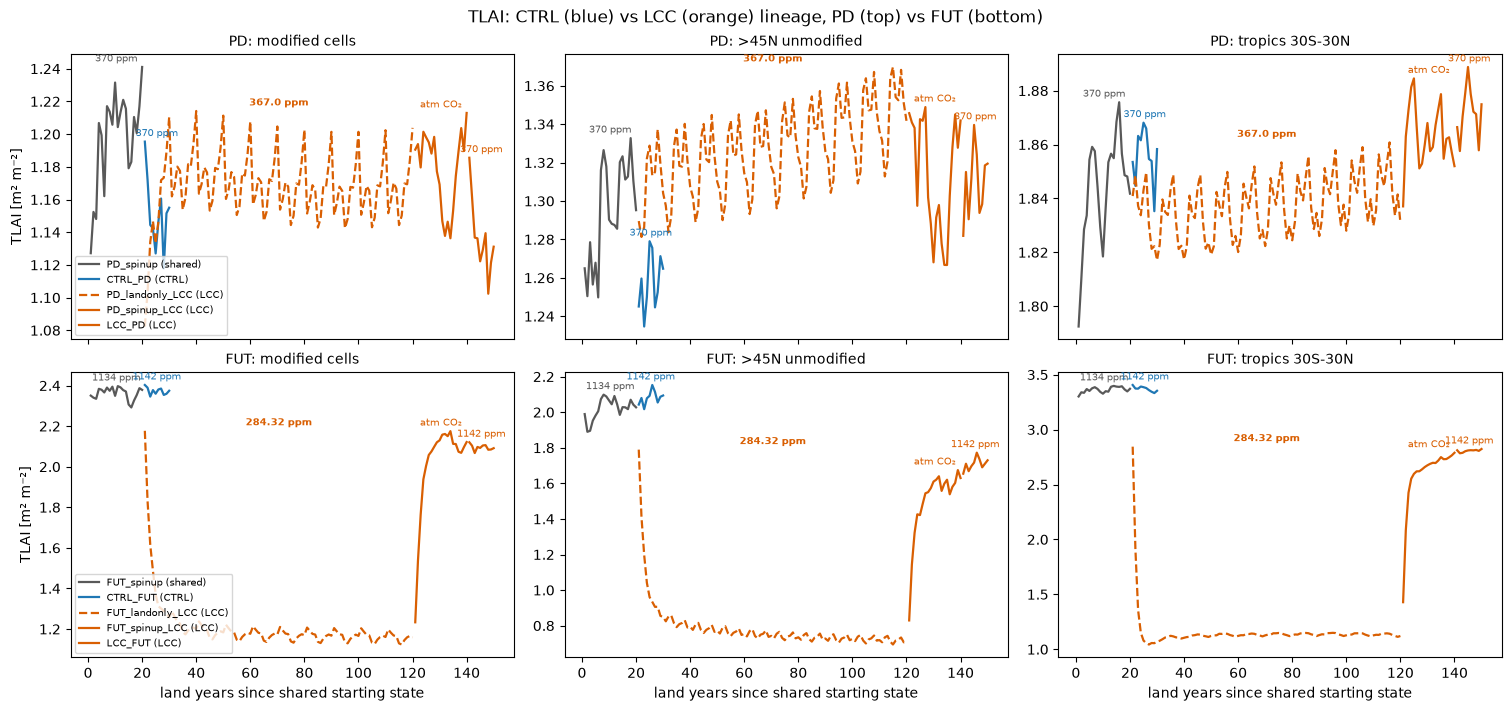

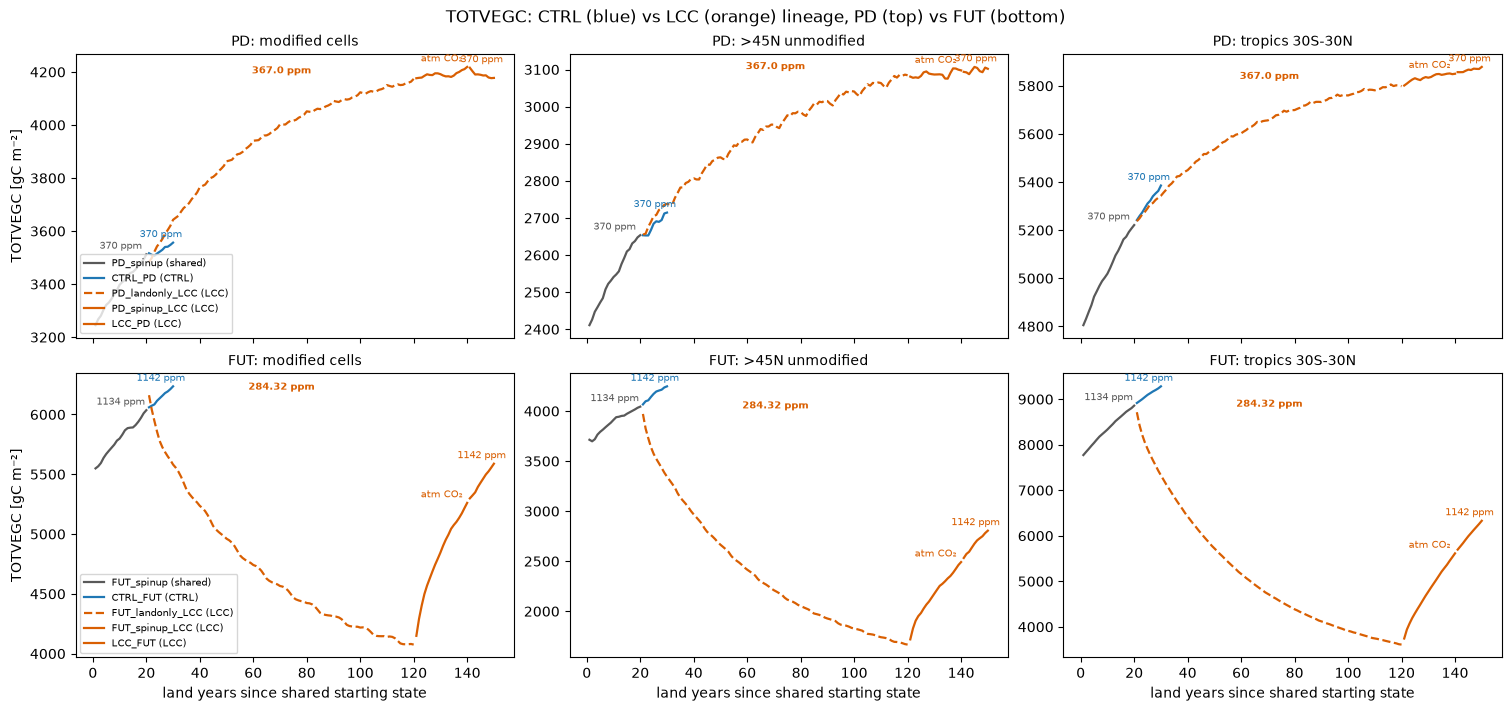

In [5]:
def lineage_figure(v, units):
    fig, axes = plt.subplots(2, len(REGIONS), figsize=(5 * len(REGIONS), 7), sharex=True, layout='constrained')
    for i, period in enumerate(['PD', 'FUT']):
        for j, region in enumerate(REGIONS):
            ax = axes[i, j]
            for stage, s in STAGES[STAGES.period == period].iterrows():
                y = SERIES[stage, region, v]
                ax.plot(AXIS[stage], y, color=COLOR[s.branch], lw=1.6, ls='--' if s.kind == 'land-only' else '-',
                        label=f'{stage} ({s.branch})')
                ppm = co2.loc[stage, 'co2_seen_ppm']
                if not np.isnan(ppm):
                    label = f'{ppm:.0f} ppm'
                elif co2.loc[stage, 'CLM_CO2_TYPE'] == 'constant':
                    label = f"{co2.loc[stage, 'CCSM_CO2_PPMV']} ppm"
                else:
                    label = 'atm CO₂'
                ax.annotate(label, (AXIS[stage].mean(), float(y.max())), textcoords='offset points',
                            xytext=(0, 4), ha='center', fontsize=7, color=COLOR[s.branch],
                            weight='bold' if s.kind == 'land-only' else 'normal')
            ax.set_title(f'{period}: {region}', fontsize=10)
            if j == 0:
                ax.set_ylabel(f'{v} [{units}]')
            if i == 1:
                ax.set_xlabel('land years since shared starting state')
        axes[i, 0].legend(fontsize=7, loc='lower left')
    fig.suptitle(f'{v}: CTRL (blue) vs LCC (orange) lineage, PD (top) vs FUT (bottom)')
    fig.savefig(OUT / f'fig1_lineage_{v}.png', dpi=150)
    plt.show()

lineage_figure('TLAI', 'm² m⁻²')
lineage_figure('TOTVEGC', 'gC m⁻²')

## 4. Why the per-run equilibrium checks did not catch it

Left: what a drift check of a single run sees. The FUT land-only TLAI in the modified cells is flat after a few years, so it "passes".
Right: what a cross-member check sees. In the nudged years, the unmodified >45°N cells (identical surfdata) differ between LCC and CTRL in FUT but hardly in PD.

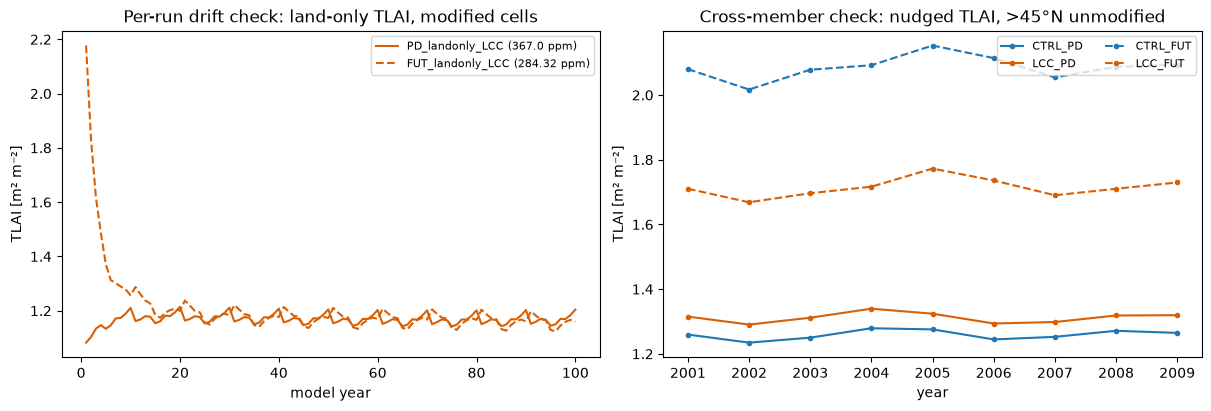

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for period, ls in [('PD', '-'), ('FUT', '--')]:
    stage = f'{period}_landonly_LCC'
    y = SERIES[stage, 'modified cells', 'TLAI']
    axes[0].plot(y.year, y, ls=ls, color=COLOR['LCC'], label=f'{stage} ({co2.loc[stage, "CCSM_CO2_PPMV"]} ppm)')
axes[0].set(title='Per-run drift check: land-only TLAI, modified cells', xlabel='model year', ylabel='TLAI [m² m⁻²]')
axes[0].legend(fontsize=8)
for period, ls in [('PD', '-'), ('FUT', '--')]:
    for branch in ('CTRL', 'LCC'):
        y = SERIES[f'{branch}_{period}', '>45N unmodified', 'TLAI'].sel(year=slice(*NUDGED_YEARS))
        axes[1].plot(y.year, y, ls=ls, marker='o', ms=3, color=COLOR[branch], label=f'{branch}_{period}')
axes[1].set(title='Cross-member check: nudged TLAI, >45°N unmodified', xlabel='year', ylabel='TLAI [m² m⁻²]')
axes[1].legend(fontsize=8, ncol=2)
fig.savefig(OUT / 'fig2_drift_vs_cross_member.png', dpi=150)
plt.show()

## 5. Consequences for the analysis: LCC − CTRL, 2001–2009

Difference of the 9-year regional means, in % of CTRL, for PD (correct CO₂) and FUT (CO₂ bug). HTOP = canopy top height and TSAI = stem area index; together with TLAI they set the snow masking (albedo). TLAI also drives MEGAN.

period                      PD   FUT
region          variable            
>45N unmodified GPP        2.6  -9.6
                HTOP       5.4 -20.2
                TLAI       4.2 -17.8
                TOTVEGC   15.4 -35.5
                TSAI       2.3  -9.1
modified cells  GPP       -1.5  -7.3
                HTOP      12.7  -0.9
                TLAI      -1.3 -11.7
                TOTVEGC   18.6 -11.3
                TSAI       0.9  -7.1
tropics 30S-30N GPP       -0.4 -11.0
                HTOP       3.9 -18.3
                TLAI       0.9 -16.6
                TOTVEGC   10.2 -33.7
                TSAI       2.2  -4.1

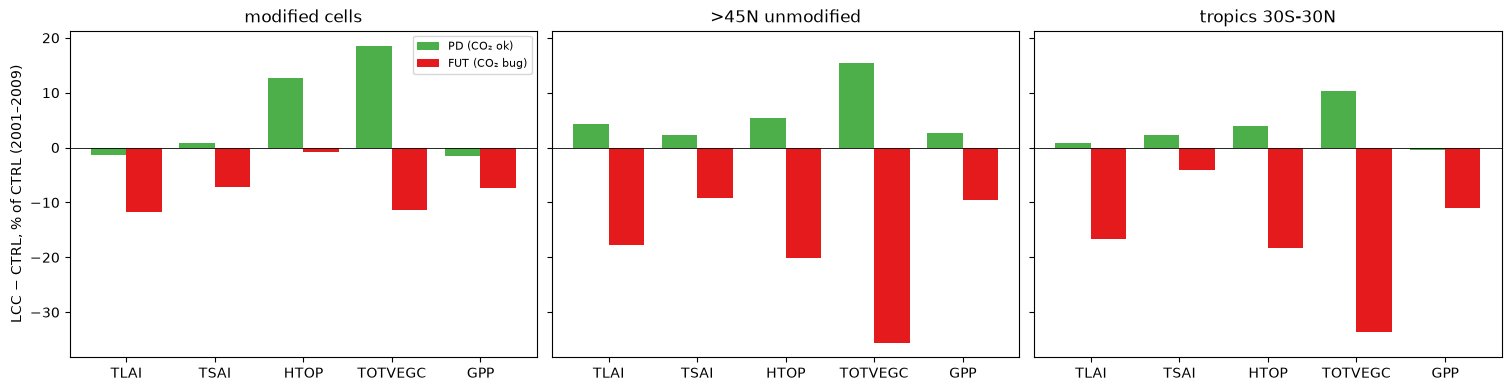

In [7]:
rows = []
for period in ('PD', 'FUT'):
    for region in REGIONS:
        for v in VARS:
            c = SERIES[f'CTRL_{period}', region, v].sel(year=slice(*NUDGED_YEARS))
            l = SERIES[f'LCC_{period}', region, v].sel(year=slice(*NUDGED_YEARS))
            rows.append(dict(period=period, region=region, variable=v, CTRL=float(c.mean()), LCC=float(l.mean()),
                             delta_pct=float(100 * (l.mean() - c.mean()) / c.mean()),
                             p_welch=stats.ttest_ind(l.values, c.values, equal_var=False).pvalue))
endstate = pd.DataFrame(rows)
endstate.to_csv(OUT / 'endstate_LCC_minus_CTRL.csv', index=False)
display(endstate.pivot_table(index=['region', 'variable'], columns='period', values='delta_pct')[['PD', 'FUT']].round(1))

fig, axes = plt.subplots(1, len(REGIONS), figsize=(5 * len(REGIONS), 3.8), sharey=True, layout='constrained')
x = np.arange(len(VARS))
for ax, region in zip(axes, REGIONS):
    sub = endstate[endstate.region == region].set_index(['period', 'variable']).delta_pct
    ax.bar(x - 0.2, [sub['PD', v] for v in VARS], 0.4, color='#4daf4a', label='PD (CO₂ ok)')
    ax.bar(x + 0.2, [sub['FUT', v] for v in VARS], 0.4, color='#e41a1c', label='FUT (CO₂ bug)')
    ax.axhline(0, color='k', lw=0.6)
    ax.set(xticks=x, xticklabels=VARS, title=region)
axes[0].set_ylabel('LCC − CTRL, % of CTRL (2001–2009)')
axes[0].legend(fontsize=8)
fig.savefig(OUT / 'fig3_endstate_PD_vs_FUT.png', dpi=150)
plt.show()

## 6. Trends: is anything still drifting?

OLS trend over the last 10 years of each stage, in % per decade of that stage's mean, with the interannual SD (in % of the mean) for scale.

In [8]:
rows = []
for (stage, region, v), y in SERIES.items():
    if v not in LINEAGE_VARS + ['GPP']:
        continue
    last = y.isel(year=slice(-10, None))
    slope = 10 * np.polyfit(last.year.values.astype(float), last.values, 1)[0]
    rows.append(dict(stage=stage, region=region, variable=v,
                     trend_pct_per_decade=100 * slope / float(last.mean()),
                     iav_sd_pct=100 * float(last.std(ddof=1) / last.mean())))
trends = pd.DataFrame(rows)
trends.to_csv(OUT / 'trends_last10yr.csv', index=False)
display(trends.pivot_table(index=['variable', 'region'], columns='stage',
                           values='trend_pct_per_decade')[list(STAGES.index)].round(1))

stage                     PD_spinup  CTRL_PD  PD_landonly_LCC  PD_spinup_LCC  \
variable region                                                                
GPP      >45N unmodified       -0.0      0.2              1.1            5.1   
         modified cells         4.5      1.0              5.3           10.3   
         tropics 30S-30N       -1.6      0.3             -1.8           -0.9   
TLAI     >45N unmodified        2.0      1.6              2.5            5.7   
         modified cells         1.2     -3.0              3.4            7.4   
         tropics 30S-30N       -0.1     -0.3             -0.7           -0.5   
TOTVEGC  >45N unmodified        4.7      2.8              1.2            0.7   
         modified cells         3.2      1.5              0.6            1.0   
         tropics 30S-30N        3.9      2.9              0.3            0.2   

stage                     LCC_PD  FUT_spinup  CTRL_FUT  FUT_landonly_LCC  \
variable region                                                            
GPP      >45N unmodified    -0.3         0.4      -0.3               0.3   
         modified cells     -1.7        -0.4       1.1              -1.8   
         tropics 30S-30N     0.8        -0.3      -0.9              -1.2   
TLAI     >45N unmodified     1.5        -0.8       2.5              -0.9   
         modified cells     -4.9        -1.2      -1.0              -3.0   
         tropics 30S-30N     0.2         0.1      -1.8              -2.0   
TOTVEGC  >45N unmodified     0.4         3.1       4.9              -4.7   
         modified cells     -0.9         3.5       3.3              -2.0   
         tropics 30S-30N     0.4         5.9       4.4              -3.8   

stage                     FUT_spinup_LCC  LCC_FUT  
variable region                                    
GPP      >45N unmodified             1.3     -0.9  
         modified cells             -3.9      0.7  
         tropics 30S-30N             0.0     -0.3  
TLAI     >45N unmodified             1.6      3.4  
         modified cells             -4.3     -0.8  
         tropics 30S-30N             3.7      0.9  
TOTVEGC  >45N unmodified            12.8     11.3  
         modified cells              7.5      6.1  
         tropics 30S-30N            15.9     11.7

## 7. Recovery after CO₂ is restored (FUT LCC branch)

Fit X(t) = A − B·exp(−t/τ) to the LCC series from the start of the coupled spin-up (land year 121) to the end of LCC_FUT (150). Then estimate when it would reach the CTRL_FUT 2001–2009 level. This is descriptive: it extrapolates a 30-year record (b).

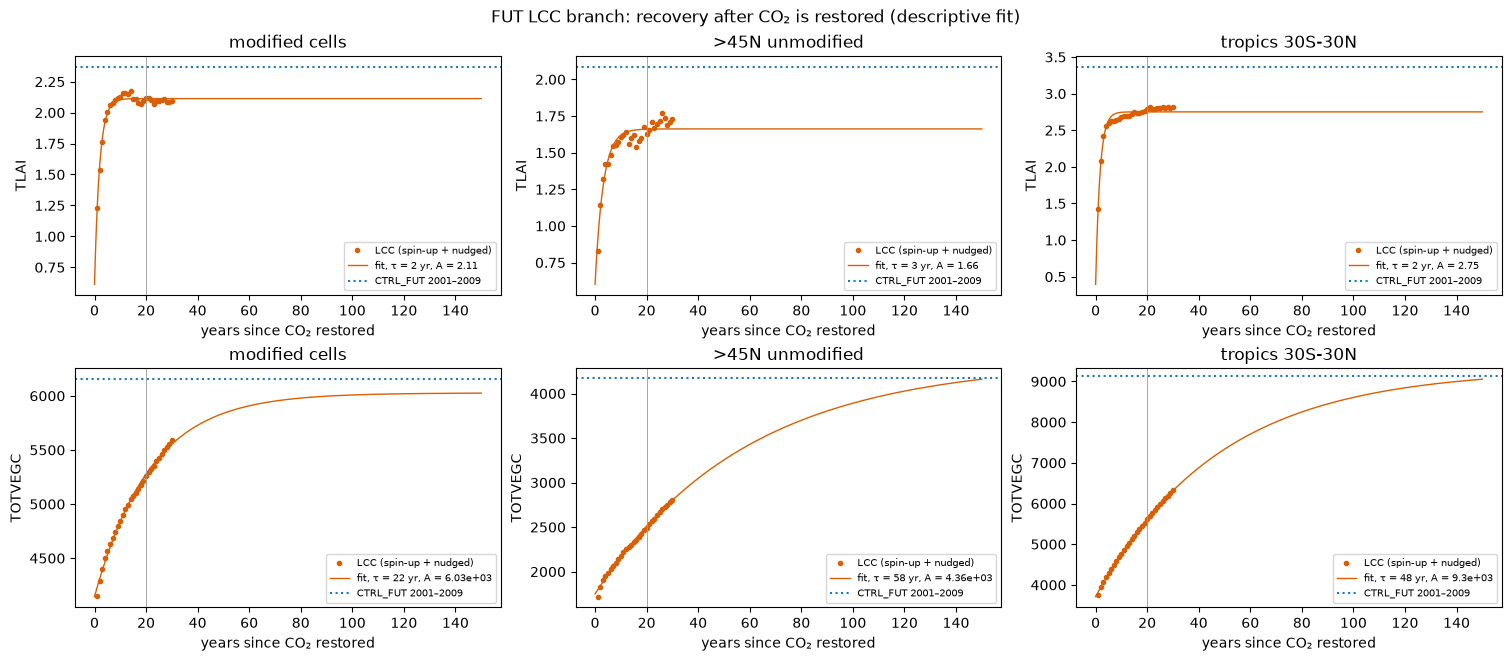

,region,variable,tau_yr,asymptote,ctrl_level,now,years_to_reach_ctrl,gap_now_pct
0,modified cells,TLAI,1.96,2.11,2.37,2.09,inf,-11.74
1,>45N unmodified,TLAI,3.13,1.66,2.09,1.73,inf,-17.06
2,tropics 30S-30N,TLAI,1.66,2.75,3.37,2.82,inf,-16.12
3,modified cells,TOTVEGC,21.73,6026.84,6153.63,5588.40,inf,-9.19
4,>45N unmodified,TOTVEGC,58.17,4359.09,4179.55,2805.25,155.66,-32.88
5,tropics 30S-30N,TOTVEGC,47.79,9297.29,9124.91,6329.32,166.22,-30.64


In [9]:
def recovery(region, v):
    t = np.r_[AXIS['FUT_spinup_LCC'], AXIS['LCC_FUT']] - 120.0
    y = np.r_[SERIES['FUT_spinup_LCC', region, v].values, SERIES['LCC_FUT', region, v].values]
    target = float(SERIES['CTRL_FUT', region, v].sel(year=slice(*NUDGED_YEARS)).mean())
    f = lambda t, A, B, tau: A - B * np.exp(-t / tau)
    p, _ = optimize.curve_fit(f, t, y, p0=(y[-1] * 1.2, y[-1] - y[0], 30), maxfev=20000)
    A, B, tau = p
    reach = tau * np.log(B / (A - target)) if A > target else np.inf
    return t, y, f, p, target, reach

rows = []
fig, axes = plt.subplots(len(LINEAGE_VARS), len(REGIONS), figsize=(5 * len(REGIONS), 6.5), layout='constrained')
for i, v in enumerate(LINEAGE_VARS):
    for j, region in enumerate(REGIONS):
        ax = axes[i, j]
        t, y, f, p, target, reach = recovery(region, v)
        tt = np.linspace(0, 150, 300)
        ax.plot(t, y, 'o', ms=3, color=COLOR['LCC'], label='LCC (spin-up + nudged)')
        ax.plot(tt, f(tt, *p), color=COLOR['LCC'], lw=1, label=f'fit, τ = {p[2]:.0f} yr, A = {p[0]:.3g}')
        ax.axhline(target, color=COLOR['CTRL'], ls=':', label='CTRL_FUT 2001–2009')
        ax.axvline(20, color='0.6', lw=0.6)
        ax.set(title=f'{region}', xlabel='years since CO₂ restored', ylabel=v)
        ax.legend(fontsize=7)
        rows.append(dict(region=region, variable=v, tau_yr=p[2], asymptote=p[0], ctrl_level=target,
                         now=float(y[-1]), years_to_reach_ctrl=reach,
                         gap_now_pct=100 * (y[-1] - target) / target))
fig.suptitle('FUT LCC branch: recovery after CO₂ is restored (descriptive fit)')
fig.savefig(OUT / 'fig4_recovery_fit.png', dpi=150)
plt.show()
recov = pd.DataFrame(rows)
recov.to_csv(OUT / 'recovery_fit.csv', index=False)
display(recov.round(2))

## Summary (run 2026-10-22; numbers from `check_CO2_bug_in_land_only_outputs/`)

👉 **The FUT land-only spin-up ran at 284 ppm instead of ≈1140 ppm. The FUT LCC vegetation collapsed and, 29 years after CO₂ was restored, is still 12–18 % below CTRL in leaf area and 9–33 % below in vegetation carbon. The PD lineage, with correct CO₂, shows no collapse.**

**1. CO₂ per stage (a, `co2_per_stage.csv`).**
- Only `FUT_landonly_LCC` runs at a CO₂ that differs from its coupled neighbours: `constant` 284.32 ppm, against `diagnostic` 1134–1142 ppm.
- The cplhist forcing contains `Sa_co2diag` ≈ 1134 ppm and datm reads it (`datm.streams.txt.CPLHISTForcing.State3hr`), but `CLM_CO2_TYPE = constant` makes CLM ignore it.
- PD land-only: `constant` 367 ppm against 370 ppm coupled, so PD is consistent by coincidence of the compset default (b).

**2. The collapse (fig. 1, (a)).**
- FUT LCC TLAI drops within ~5 years of the land-only start: modified cells 2.4 → 1.2, >45°N unmodified 2.0 → 0.75, tropics 3.4 → 1.1.
- It stays flat for 100 years, then jumps back as soon as CO₂ is restored in the coupled stage.
- PD land-only stays within ±0.05 of its coupled level. The ~10-yr sawtooth in the land-only stages is the cplhist forcing looping over its years 11–20.

**3. Why the per-run checks did not see it (fig. 2, (a)).**
- After year ~15, FUT land-only TLAI in the modified cells is flat and almost identical to PD land-only (~1.17), so a drift test passes.
- The cross-member test does not: in 2001–2009, >45°N unmodified TLAI is 1.26 vs 1.31 in PD (CTRL vs LCC), but 2.08 vs 1.72 in FUT.

**4. Consequences for the region (fig. 3, `endstate_LCC_minus_CTRL.csv`, (a); interpretation (b)).** LCC − CTRL, 2001–2009, % of CTRL:

| | TLAI | TSAI | HTOP | TOTVEGC | GPP |
|---|---|---|---|---|---|
| modified cells, PD | −1.3 | +0.9 | +12.7 | +18.6 | −1.5 |
| modified cells, FUT | **−11.7** | −7.1 | **−0.9** | **−11.3** | −7.3 |
| >45°N unmodified, PD | +4.2 | +2.3 | +5.4 | +15.4 | +2.6 |
| >45°N unmodified, FUT | **−17.8** | −9.1 | −20.2 | −35.5 | −9.6 |
| tropics, PD | +0.9 | +2.2 | +3.9 | +10.2 | −0.4 |
| tropics, FUT | −16.6 | −4.1 | −18.3 | −33.7 | −11.0 |

- In PD, forest expansion makes canopies taller (+13 % HTOP) and adds carbon. In FUT this local signal is cancelled or reversed by the bug.
- Snow masking and MEGAN emissions in the region are therefore biased, probably toward too little albedo change and too low emissions (b).
- PD also carries a lineage offset (+4 % TLAI, +15 % TOTVEGC in unmodified >45°N; +10 % TOTVEGC in the tropics). It comes from the 140- vs 20-yr asymmetry at correct CO₂: smaller, opposite in sign, but not zero.

**5. Recovery after CO₂ is restored (fig. 4, `recovery_fit.csv`; descriptive, (b)).**
- **TLAI** recovers fast (τ ≈ 2–3 yr), but to a plateau 12–17 % below CTRL_FUT. The single-exponential fit says it would never reach CTRL.
- The >45°N TLAI is still rising (+3.4 %/decade in LCC_FUT), so the plateau may be pinned to slow pools such as stem, nitrogen or soil (b). A single exponential is too simple.
- **TOTVEGC** recovers with τ ≈ 22 yr (modified cells) to 48–58 yr (tropics, >45°N unmodified). It would reach the CTRL level after ~155–165 yr. In the modified cells its asymptote is about 2 % below CTRL.
- So a longer coupled spin-up is not a practical repair. Redoing the land-only stage with the right CO₂ is.

**Not checked (c):** other differences between land-only and coupled forcing (e.g. N deposition, the fidelity of the cplhist climate); the lnd_in of the land-only run (the run directory was cleaned).